# Tugas III – STIK4121 Metode Statistik
## Analisis Variansi (ANOVA) Dua Arah

**Kasus:** Seorang tutor ingin mengetahui apakah nilai kuis mahasiswa dipengaruhi oleh **metode belajar utama** (Faktor A) dan **intensitas akses tuton** (Faktor B), serta apakah terdapat **interaksi** antara keduanya.

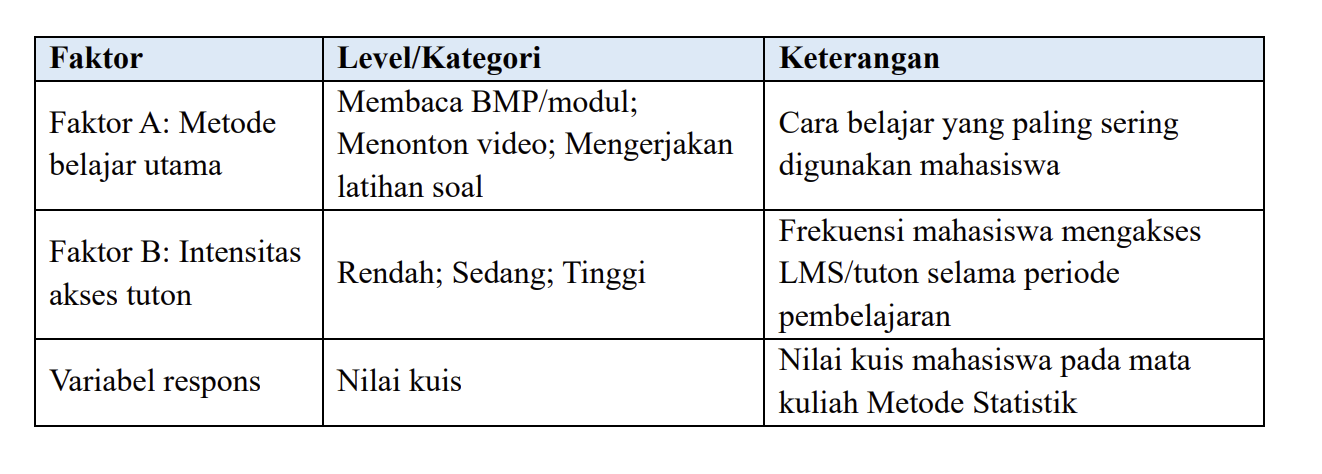

In [1]:
alpha <- 0.05
options(digits = 6, repr.plot.width = 12, repr.plot.height = 5.5)

lv_metode <- c("Membaca BMP/modul", "Menonton video", "Mengerjakan latihan soal")
lv_tuton  <- c("Rendah", "Sedang", "Tinggi")

df <- data.frame(
  Metode = factor(rep(lv_metode, each = 9), levels = lv_metode),
  Tuton  = factor(rep(rep(lv_tuton, each = 3), times = 3), levels = lv_tuton),
  Nilai  = c(64, 65, 66, 70, 72, 74, 76, 78, 80,
             67, 68, 69, 73, 75, 77, 78, 80, 82,
             70, 72, 74, 80, 82, 84, 88, 90, 92)
)
df

Metode,Tuton,Nilai
<fct>,<fct>,<dbl>
Membaca BMP/modul,Rendah,64
Membaca BMP/modul,Rendah,65
Membaca BMP/modul,Rendah,66
Membaca BMP/modul,Sedang,70
Membaca BMP/modul,Sedang,72
Membaca BMP/modul,Sedang,74
Membaca BMP/modul,Tinggi,76
Membaca BMP/modul,Tinggi,78
Membaca BMP/modul,Tinggi,80


### Soal 1. Apa variabel respons dalam penelitian ini?

**Jawaban:**

Variabel respons adalah **nilai kuis** mahasiswa pada mata kuliah Metode Statistik. Di table terlihat hanya `Nilai` yang bertipe numerik, dengan rentang 64–92 dan rata-rata 75,78. Variabel inilah yang diukur dan dibandingkan antarkelompok.

### Apa faktor pertama dan faktor kedua?

**Jawaban:*


- **Faktor pertama (A):** metode belajar utama Metode
- **Faktor kedua (B):** intensitas akses tuton


### Soal 2. Sebutkan level/kategori masing-masing faktor

**Jawaban:**

- **Faktor A (3 level):** membaca BMP/modul, menonton video, mengerjakan latihan soal.
- **Faktor B (3 level):** rendah, sedang, tinggi.

Jadi rancangannya faktorial **3 × 3 = 9 kombinasi perlakuan**.

### Soal 3. Mengapa data ini sesuai dianalisis dengan ANOVA dua arah?

In [7]:
cat("Respons numerik?      ", is.numeric(df$Nilai), "\n")
cat("Dua faktor kategorik? ", is.factor(df$Metode) & is.factor(df$Tuton), "\n\n")
cat("Banyak ulangan per kombinasi (sel):\n")
tab_n <- table(df$Metode, df$Tuton)
print(tab_n)
cat("\nSemua sel terisi & seimbang?", all(tab_n == tab_n[1]), " | ulangan per sel =", tab_n[1], "\n")

Respons numerik?       TRUE 
Dua faktor kategorik?  TRUE 

Banyak ulangan per kombinasi (sel):
                          
                           Rendah Sedang Tinggi
  Membaca BMP/modul             3      3      3
  Menonton video                3      3      3
  Mengerjakan latihan soal      3      3      3

Semua sel terisi & seimbang? TRUE  | ulangan per sel = 3 


**Jawaban:**

Syarat ANOVA dua arah dengan interaksi terpenuhi:

1. Ada **satu variabel respons numerik** (`Nilai`).
2. Ada **dua faktor kategorik** yang diteliti bersamaan, masing-masing 3 level.
3. Tabel di atas menunjukkan **semua 9 kombinasi terisi** dengan ulangan yang **sama (3 mahasiswa per sel)**. Rancangannya seimbang dan memiliki ulangan, sehingga JK interaksi bisa dipisahkan dari JK galat.

Karena itu dapat diuji sekaligus pengaruh utama metode, pengaruh utama tuton, dan interaksinya. Ini sesuai dengan tujuan tutor.

### Soal 4. Apa perbedaan ANOVA satu arah dan dua arah dalam kasus ini?

In [ ]:
satu_arah <- aov(Nilai ~ Metode, data = df)           # hanya faktor metode
dua_arah  <- aov(Nilai ~ Metode * Tuton, data = df)   # metode, tuton, interaksi

cat("===== ANOVA SATU ARAH (Metode saja) =====\n"); print(summary(satu_arah))
cat("\n===== ANOVA DUA ARAH (Metode * Tuton) =====\n"); print(summary(dua_arah))

s1 <- summary(satu_arah)[[1]]; s2 <- summary(dua_arah)[[1]]
cat(sprintf("\nMeans square  : satu arah = %.3f  vs  dua arah = %.3f\n", s1["Residuals", "Mean Sq"], s2["Residuals", "Mean Sq"]))
cat(sprintf("F Metode   : satu arah = %.3f  vs  dua arah = %.3f\n",  s1["Metode", "F value"],   s2["Metode", "F value"]))

===== ANOVA SATU ARAH (Metode saja) =====
            Df Sum Sq Mean Sq F value Pr(>F)  
Metode       2    449   224.3    5.28  0.013 *
Residuals   24   1020    42.5                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

===== ANOVA DUA ARAH (Metode * Tuton) =====
             Df Sum Sq Mean Sq F value  Pr(>F)    
Metode        2    449     224   67.30 4.4e-09 ***
Tuton         2    929     464  139.30 1.1e-11 ***
Metode:Tuton  4     31       8    2.35   0.093 .  
Residuals    18     60       3                    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

KT galat  : satu arah = 42.500  vs  dua arah = 3.333
F Metode   : satu arah = 5.278  vs  dua arah = NA


**Jawaban:**

- **ANOVA satu arah** hanya menguji satu faktor. Pada output di atas, variasi akibat intensitas tuton (JK = 928,67) dan interaksi (JK = 31,33) **ikut masuk ke galat**. Akibatnya JK galat menjadi 1020 dan Means square = 42,50, sehingga F metode hanya **5,28** (p = 0,0126).
- **ANOVA dua arah** memecah variasi total menjadi JK A, JK B, JK AB, dan JK galat. Means square turun menjadi **3,33**, sehingga F metode naik menjadi **67,30**.

Jadi ANOVA dua arah lebih **efisien dan peka**, menguji dua faktor sekaligus, dan dapat menguji apakah efek metode **bergantung** pada tingkat akses tuton (interaksi). ANOVA satu arah tidak bisa melakukan hal itu.

### Soal 5. Rumuskan hipotesis pengaruh utama metode belajar

In [9]:
rata_metode <- tapply(df$Nilai, df$Metode, mean)
round(rata_metode, 2)

Membaca BMP/modul           Menonton video Mengerjakan latihan soal 
                   71.67                    74.33                    81.33

**Jawaban:**

Yang dibandingkan adalah rata-rata nilai tiap metode, yaitu μ₁, μ₂, μ₃ di atas.

- **H₀:** μ_BMP = μ_video = μ_latihan. Metode belajar tidak berpengaruh terhadap nilai kuis.
- **H₁:** minimal ada satu μ_i yang berbeda. Metode belajar berpengaruh terhadap nilai kuis.

### Soal 6. Rumuskan hipotesis pengaruh utama intensitas akses tuton

In [10]:
rata_tuton <- tapply(df$Nilai, df$Tuton, mean)
round(rata_tuton, 2)

Rendah Sedang Tinggi 
 68.33  76.33  82.67

**Jawaban:**

- **H₀:** μ_rendah = μ_sedang = μ_tinggi. Intensitas akses tuton tidak berpengaruh terhadap nilai kuis.
- **H₁:** minimal ada satu μ_j yang berbeda. Intensitas akses tuton berpengaruh terhadap nilai kuis.

### Soal 7. Jelaskan makna interaksi dan rumuskan hipotesisnya

                         Rendah Sedang Tinggi Rata-rata Metode
Membaca BMP/modul         65.00  72.00  78.00            71.67
Menonton video            68.00  75.00  80.00            74.33
Mengerjakan latihan soal  72.00  82.00  90.00            81.33
Rata-rata Tuton           68.33  76.33  82.67            75.78

Selisih (Latihan soal - Membaca BMP) per tingkat tuton:
Rendah Sedang Tinggi 
     7     10     12 


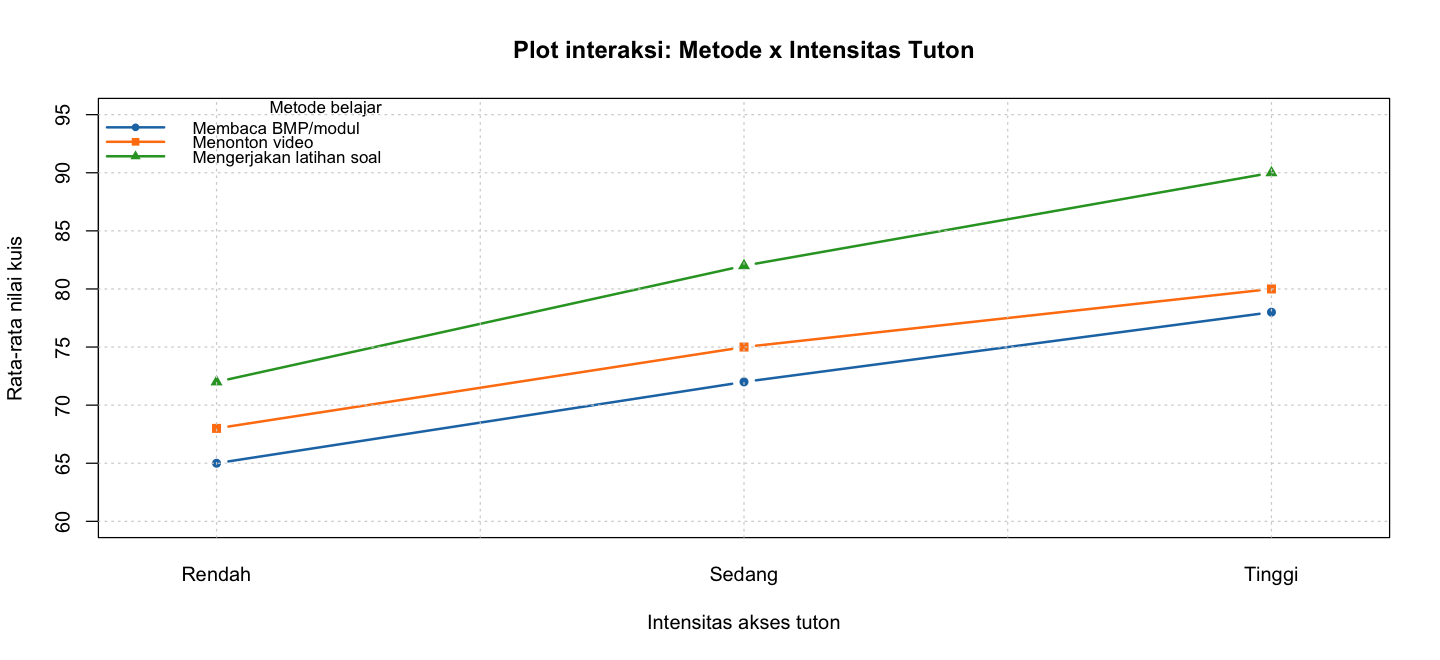

In [11]:
# Tabel rata-rata sel
tabel_rata <- tapply(df$Nilai, list(df$Metode, df$Tuton), mean)
tabel_rata <- cbind(tabel_rata, "Rata-rata Metode" = tapply(df$Nilai, df$Metode, mean))
tabel_rata <- rbind(tabel_rata, "Rata-rata Tuton" = c(tapply(df$Nilai, df$Tuton, mean), mean(df$Nilai)))
print(round(tabel_rata, 2))

# Selisih Latihan - BMP di tiap tingkat tuton (jika tanpa interaksi, selisihnya konstan)
cat("\nSelisih (Latihan soal - Membaca BMP) per tingkat tuton:\n")
print(tabel_rata["Mengerjakan latihan soal", 1:3] - tabel_rata["Membaca BMP/modul", 1:3])

# Plot interaksi
warna <- c("#1f77b4", "#ff7f0e", "#2ca02c")
interaction.plot(x.factor = df$Tuton, trace.factor = df$Metode, response = df$Nilai,
                 type = "b", pch = c(16, 15, 17), col = warna, lty = 1, lwd = 2,
                 legend = FALSE, ylim = c(60, 95),
                 xlab = "Intensitas akses tuton", ylab = "Rata-rata nilai kuis",
                 main = "Plot interaksi: Metode x Intensitas Tuton")
legend("topleft", legend = lv_metode, col = warna, pch = c(16, 15, 17), lwd = 2,
       bty = "n", title = "Metode belajar", cex = 0.85)
grid()

**Jawaban:**

**Interaksi** berarti pengaruh metode belajar terhadap nilai kuis **tidak sama** pada setiap tingkat akses tuton. Dengan kata lain, efek satu faktor bergantung pada level faktor lain. Jika tidak ada interaksi, selisih antarmetode akan **konstan** di semua tingkat tuton, dan garis pada plot interaksi akan **sejajar**.

Di data ini selisih Latihan − BMP adalah 7 → 10 → 12. Selisihnya sedikit melebar, dan garisnya hampir sejajar. Signifikansinya diuji di Soal 10.

- **H₀:** (αβ)_ij = 0 untuk semua i, j. Tidak ada interaksi antara metode belajar dan intensitas tuton.
- **H₁:** minimal ada satu (αβ)_ij ≠ 0. Ada interaksi antara metode belajar dan intensitas tuton.

### A. Perhitungan ANOVA dua arah secara manual

Model: $Y_{ijk} = \mu + \alpha_i + \beta_j + (\alpha\beta)_{ij} + \varepsilon_{ijk}$

dengan $a = 3$ level metode, $b = 3$ level tuton, $n = 3$ ulangan.

- $JK_T = \sum (Y_{ijk} - \bar{Y}_{...})^2$
- $JK_A = bn \sum_i (\bar{Y}_{i..} - \bar{Y}_{...})^2$
- $JK_B = an \sum_j (\bar{Y}_{.j.} - \bar{Y}_{...})^2$
- $JK_G = \sum (Y_{ijk} - \bar{Y}_{ij.})^2$
- $JK_{AB} = JK_T - JK_A - JK_B - JK_G$

In [12]:
a  <- nlevels(df$Metode)
b  <- nlevels(df$Tuton)
n  <- unique(as.vector(table(df$Metode, df$Tuton)))   # ulangan per sel (= 3)
N  <- nrow(df)
y  <- df$Nilai
gm <- mean(y)

mean_A  <- tapply(y, df$Metode, mean)
mean_B  <- tapply(y, df$Tuton, mean)
mean_AB <- ave(y, df$Metode, df$Tuton)                 # rata-rata sel untuk tiap observasi

JK_T  <- sum((y - gm)^2)
JK_A  <- b * n * sum((mean_A - gm)^2)
JK_B  <- a * n * sum((mean_B - gm)^2)
JK_G  <- sum((y - mean_AB)^2)
JK_AB <- JK_T - JK_A - JK_B - JK_G

db_A <- a - 1; db_B <- b - 1; db_AB <- (a - 1) * (b - 1); db_G <- a * b * (n - 1); db_T <- N - 1

cat(sprintf("Rata-rata umum = %.3f\n", gm))
cat(sprintf("JK Total = %.3f | JK A = %.3f | JK B = %.3f | JK AB = %.3f | JK Galat = %.3f\n",
            JK_T, JK_A, JK_B, JK_AB, JK_G))

Rata-rata umum = 75.778
JK Total = 1468.667 | JK A = 448.667 | JK B = 928.667 | JK AB = 31.333 | JK Galat = 60.000


### B. Tabel ANOVA

In [13]:
JK <- c(JK_A, JK_B, JK_AB, JK_G, JK_T)
db <- c(db_A, db_B, db_AB, db_G, db_T)
KT <- c(JK[1:4] / db[1:4], NA)
KT_G <- KT[4]

F_hit <- c(KT[1:3] / KT_G, NA, NA)
F_tab <- c(qf(1 - alpha, db[1:3], db_G), NA, NA)
p_val <- c(pf(F_hit[1:3], db[1:3], db_G, lower.tail = FALSE), NA, NA)
keputusan <- ifelse(is.na(p_val), "",
             ifelse(p_val < alpha, "Tolak H0 (signifikan)", "Gagal tolak H0"))

tabel_anova <- data.frame(
  "Sumber variasi"   = c("Metode belajar (A)", "Intensitas tuton (B)", "Interaksi A x B", "Galat", "Total"),
  "JK"               = round(JK, 3),
  "db"               = db,
  "KT"               = round(KT, 3),
  "F hitung"         = round(F_hit, 3),
  "F tabel (a=0,05)" = round(F_tab, 3),
  "p-value"          = signif(p_val, 4),
  "Keputusan"        = keputusan,
  check.names = FALSE
)
tabel_anova

Sumber variasi,JK,db,KT,F hitung,"F tabel (a=0,05)",p-value,Keputusan
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Metode belajar (A),448.667,2,224.333,67.30,3.555,4.420e-09,Tolak H0 (signifikan)
Intensitas tuton (B),928.667,2,464.333,139.30,3.555,1.117e-11,Tolak H0 (signifikan)
Interaksi A x B,31.333,4,7.833,2.35,2.928,9.315e-02,Gagal tolak H0
Galat,60.000,18,3.333,NA,NA,NA,
Total,1468.667,26,NA,NA,NA,NA,


### C. Verifikasi dengan `aov()`
Karena rancangannya seimbang, hasilnya harus sama persis dengan tabel manual.

In [14]:
model <- aov(Nilai ~ Metode * Tuton, data = df)
summary(model)

             Df Sum Sq Mean Sq F value  Pr(>F)    
Metode        2    449     224   67.30 4.4e-09 ***
Tuton         2    929     464  139.30 1.1e-11 ***
Metode:Tuton  4     31       8    2.35   0.093 .  
Residuals    18     60       3                    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

### D. Uji asumsi

In [15]:
# Normalitas residual
print(shapiro.test(residuals(model)))

# Homogenitas varians: Levene (center = median), dihitung dengan base R
sel <- interaction(df$Metode, df$Tuton)
dev <- abs(df$Nilai - ave(df$Nilai, sel, FUN = median))
cat("Uji Levene (center = median):\n")
print(summary(aov(dev ~ sel)))

# Pembanding: Bartlett
bartlett.test(Nilai ~ sel, data = df)


	Shapiro-Wilk normality test

data:  residuals(model)
W = 0.8543, p-value = 0.0014

Uji Levene (center = median):
            Df Sum Sq Mean Sq F value Pr(>F)
sel          8   2.07   0.259    0.23   0.98
Residuals   18  20.00   1.111               



	Bartlett test of homogeneity of variances

data:  Nilai by sel
Bartlett's K-squared = 1.91, df = 8, p-value = 0.984


**Catatan asumsi:** Uji Levene menunjukkan varians antarkelompok homogen. Uji Shapiro-Wilk memberi p < 0,05, tetapi ini terjadi karena data soal disusun simetris (setiap sel berselisih tepat ±1 atau ±2 dari rata-ratanya), sehingga residual hanya bernilai beberapa angka diskret (−2, −1, 0, 1, 2) dan tidak membentuk sebaran kontinu. Dengan rancangan seimbang (n sama di tiap sel) dan varians homogen, ANOVA cukup robust terhadap penyimpangan normalitas ini, sehingga kesimpulan uji F tetap dapat digunakan.

### Soal 8. Apakah metode belajar berpengaruh signifikan terhadap nilai kuis?

In [16]:
hasil_A <- tabel_anova[1, ]
print(hasil_A)
cat(sprintf("\nF hitung = %.3f %s F tabel = %.3f ; p-value = %.3g %s alpha = %.2f\n",
            F_hit[1], ifelse(F_hit[1] > F_tab[1], ">", "<="), F_tab[1],
            p_val[1], ifelse(p_val[1] < alpha, "<", ">="), alpha))
cat("Keputusan:", keputusan[1], "\n\n")

cat("Rata-rata per metode:\n"); print(round(rata_metode, 2))

# Uji lanjut: pasangan metode mana yang berbeda?
TukeyHSD(model, which = "Metode")

      Sumber variasi      JK db      KT F hitung F tabel (a=0,05)  p-value
1 Metode belajar (A) 448.667  2 224.333     67.3            3.555 4.42e-09
              Keputusan
1 Tolak H0 (signifikan)

F hitung = 67.300 > F tabel = 3.555 ; p-value = 4.42e-09 < alpha = 0.05
Keputusan: Tolak H0 (signifikan) 

Rata-rata per metode:
       Membaca BMP/modul           Menonton video Mengerjakan latihan soal 
                   71.67                    74.33                    81.33 


  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = Nilai ~ Metode * Tuton, data = df)

$Metode
                                              diff      lwr      upr    p adj
Menonton video-Membaca BMP/modul           2.66667 0.470114  4.86322 0.016252
Mengerjakan latihan soal-Membaca BMP/modul 9.66667 7.470114 11.86322 0.000000
Mengerjakan latihan soal-Menonton video    7.00000 4.803448  9.19655 0.000001


**Jawaban:**

**Ya, signifikan.** F hitung = 67,30 > F tabel(2; 18; 0,05) = 3,555 dan p-value < 0,001 < 0,05, sehingga **H₀ ditolak**. Metode belajar berpengaruh nyata terhadap nilai kuis.

Rata-rata tertinggi diperoleh dari latihan soal (81,33), lalu video (74,33), lalu BMP (71,67). Uji Tukey menunjukkan latihan soal berbeda nyata dari kedua metode lain, dan video juga berbeda nyata dari BMP (selisih 2,67; p < 0,05).

### Soal 9. Apakah intensitas akses tuton berpengaruh signifikan terhadap nilai kuis?

In [17]:
print(tabel_anova[2, ])
cat(sprintf("\nF hitung = %.3f %s F tabel = %.3f ; p-value = %.3g %s alpha = %.2f\n",
            F_hit[2], ifelse(F_hit[2] > F_tab[2], ">", "<="), F_tab[2],
            p_val[2], ifelse(p_val[2] < alpha, "<", ">="), alpha))
cat("Keputusan:", keputusan[2], "\n\n")

cat("Rata-rata per tingkat tuton:\n"); print(round(rata_tuton, 2))

TukeyHSD(model, which = "Tuton")

        Sumber variasi      JK db      KT F hitung F tabel (a=0,05)   p-value
2 Intensitas tuton (B) 928.667  2 464.333    139.3            3.555 1.117e-11
              Keputusan
2 Tolak H0 (signifikan)

F hitung = 139.300 > F tabel = 3.555 ; p-value = 1.12e-11 < alpha = 0.05
Keputusan: Tolak H0 (signifikan) 

Rata-rata per tingkat tuton:
Rendah Sedang Tinggi 
 68.33  76.33  82.67 


  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = Nilai ~ Metode * Tuton, data = df)

$Tuton
                  diff      lwr      upr p adj
Sedang-Rendah  8.00000  5.80345 10.19655 0e+00
Tinggi-Rendah 14.33333 12.13678 16.52989 0e+00
Tinggi-Sedang  6.33333  4.13678  8.52989 2e-06


**Jawaban:**

**Ya, signifikan.** F hitung = 139,30 > F tabel = 3,555 dan p-value < 0,001, sehingga **H₀ ditolak**. Intensitas akses tuton berpengaruh nyata terhadap nilai kuis.

Nilai naik dari 68,33 (rendah) ke 76,33 (sedang) lalu 82,67 (tinggi), dan uji Tukey menunjukkan ketiga tingkat saling berbeda nyata. F-nya paling besar, sehingga faktor inilah yang **paling kuat** pengaruhnya.

### Soal 10. Apakah terdapat interaksi yang signifikan antara metode belajar dan intensitas tuton?

In [18]:
print(tabel_anova[3, ])
cat(sprintf("\nF hitung = %.3f %s F tabel = %.3f ; p-value = %.4f %s alpha = %.2f\n",
            F_hit[3], ifelse(F_hit[3] > F_tab[3], ">", "<="), F_tab[3],
            p_val[3], ifelse(p_val[3] < alpha, "<", ">="), alpha))
cat("Keputusan:", keputusan[3], "\n")

   Sumber variasi     JK db    KT F hitung F tabel (a=0,05) p-value
3 Interaksi A x B 31.333  4 7.833     2.35            2.928 0.09315
       Keputusan
3 Gagal tolak H0

F hitung = 2.350 <= F tabel = 2.928 ; p-value = 0.0931 >= alpha = 0.05
Keputusan: Gagal tolak H0 


**Jawaban:**

**Tidak signifikan.** F hitung = 2,35 < F tabel(4; 18; 0,05) = 2,928 dan p-value = 0,093 > 0,05, sehingga **H₀ gagal ditolak**.

Pengaruh metode belajar relatif **konsisten** di semua tingkat akses tuton. Garis pada plot interaksi (Soal 7) hampir sejajar. Selisih latihan soal memang sedikit melebar pada tuton tinggi, tetapi belum signifikan secara statistik. Karena interaksi tidak signifikan, pengaruh utama pada Soal 8 dan 9 dapat **ditafsirkan langsung**.

### Soal 11. Kombinasi mana yang memiliki rata-rata nilai tertinggi?

                    Metode  Tuton Nilai
1 Mengerjakan latihan soal Tinggi    90
2 Mengerjakan latihan soal Sedang    82
3           Menonton video Tinggi    80
4        Membaca BMP/modul Tinggi    78
5           Menonton video Sedang    75
6 Mengerjakan latihan soal Rendah    72
7        Membaca BMP/modul Sedang    72
8           Menonton video Rendah    68
9        Membaca BMP/modul Rendah    65

Tertinggi: Mengerjakan latihan soal + Tinggi -> 90 
Terendah : Membaca BMP/modul + Rendah -> 65 


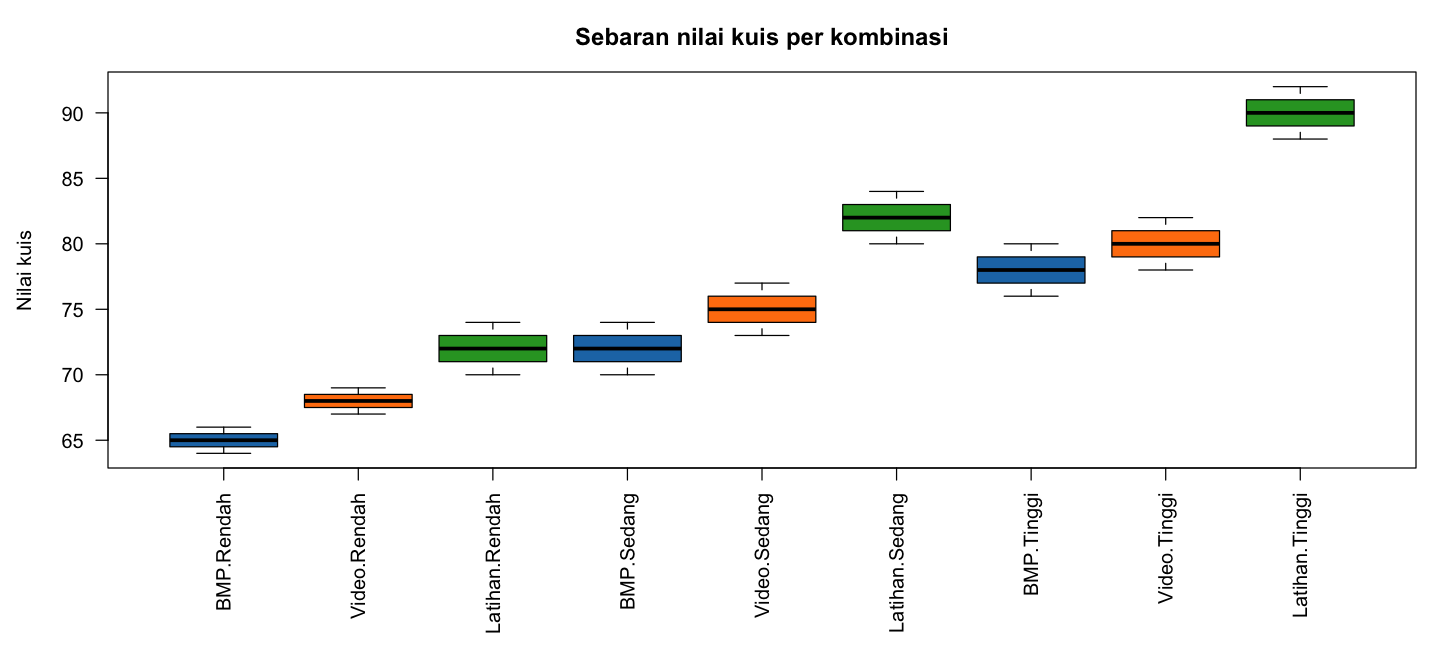

In [19]:
rata_sel <- aggregate(Nilai ~ Metode + Tuton, data = df, FUN = mean)
rata_sel <- rata_sel[order(-rata_sel$Nilai), ]
rownames(rata_sel) <- NULL
print(rata_sel)

cat("\nTertinggi:", as.character(rata_sel$Metode[1]), "+", as.character(rata_sel$Tuton[1]),
    "->", rata_sel$Nilai[1], "\n")
cat("Terendah :", as.character(rata_sel$Metode[nrow(rata_sel)]), "+",
    as.character(rata_sel$Tuton[nrow(rata_sel)]), "->", rata_sel$Nilai[nrow(rata_sel)], "\n")

# Sebaran per kombinasi
df$MetodeS <- factor(df$Metode, labels = c("BMP", "Video", "Latihan"))
par(mar = c(8, 4.5, 3, 1))
boxplot(Nilai ~ MetodeS + Tuton, data = df, las = 2, col = rep(warna, 3),
        xlab = "", ylab = "Nilai kuis", main = "Sebaran nilai kuis per kombinasi")

**Jawaban:**

Kombinasi tertinggi adalah **mengerjakan latihan soal + akses tuton tinggi**, dengan rata-rata **90** (nilai 88, 90, 92). Kombinasi terendah adalah **membaca BMP + akses tuton rendah**, dengan rata-rata **65**.

### Soal 12. Apa perbedaan ANOVA dua arah dengan regresi linier sederhana dan regresi berganda?

In [20]:
# (a) Regresi sederhana: satu prediktor kuantitatif (skor tuton 1, 2, 3)
df$SkorTuton <- as.numeric(df$Tuton)
reg_sederhana <- lm(Nilai ~ SkorTuton, data = df)
cat("===== Regresi sederhana: Nilai ~ SkorTuton =====\n")
print(coef(reg_sederhana))
cat("R-squared =", round(summary(reg_sederhana)$r.squared, 4), "\n")

# (b) Regresi berganda: dua prediktor (skor tuton + dummy metode)
reg_berganda <- lm(Nilai ~ SkorTuton + Metode, data = df)
cat("\n===== Regresi berganda: Nilai ~ SkorTuton + Metode =====\n")
print(round(coef(reg_berganda), 3))
cat("R-squared =", round(summary(reg_berganda)$r.squared, 4), "\n")

# (c) ANOVA dua arah = regresi dengan variabel dummy -> tabel ANOVA sama
cat("\n===== ANOVA dua arah lewat lm() + anova() =====\n")
print(anova(lm(Nilai ~ Metode * Tuton, data = df)))
cat("\nContoh pengodean dummy (6 baris pertama):\n")
head(model.matrix(~ Metode + Tuton, data = df))

===== Regresi sederhana: Nilai ~ SkorTuton =====
(Intercept)   SkorTuton 
   61.44444     7.16667 
R-squared = 0.6295 

===== Regresi berganda: Nilai ~ SkorTuton + Metode =====
                   (Intercept)                      SkorTuton 
                        57.333                          7.167 
          MetodeMenonton video MetodeMengerjakan latihan soal 
                         2.667                          9.667 
R-squared = 0.935 

===== ANOVA dua arah lewat lm() + anova() =====
Analysis of Variance Table

Response: Nilai
             Df Sum Sq Mean Sq F value   Pr(>F)    
Metode        2  448.7   224.3   67.30 4.42e-09 ***
Tuton         2  928.7   464.3  139.30 1.12e-11 ***
Metode:Tuton  4   31.3     7.8    2.35   0.0931 .  
Residuals    18   60.0     3.3                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Contoh pengodean dummy (6 baris pertama):


,(Intercept),MetodeMenonton video,MetodeMengerjakan latihan soal,TutonSedang,TutonTinggi
1,1,0,0,0,0
2,1,0,0,0,0
3,1,0,0,0,0
4,1,0,0,1,0
5,1,0,0,1,0
6,1,0,0,1,0


**Jawaban:**

| Aspek | Regresi sederhana | Regresi berganda | ANOVA dua arah |
|---|---|---|---|
| Variabel bebas | 1, umumnya kuantitatif | ≥ 2, umumnya kuantitatif | 2 faktor **kategorik** |
| Tujuan | Model hubungan & prediksi | Pengaruh tiap prediktor & prediksi | **Membandingkan rata-rata** antarkelompok & menguji interaksi |
| Output utama | Persamaan Ŷ = a + bX | Koefisien b₁, b₂, …, R² | Tabel ANOVA (JK, KT, F) |
| Uji | t untuk koefisien, F model | t tiap koefisien, F model | F untuk A, B, dan A×B |

Bukti dari output:
- Regresi sederhana menghasilkan persamaan **Ŷ = 61,44 + 7,17·SkorTuton** (R² = 0,629). Artinya setiap kenaikan satu tingkat tuton menambah nilai sekitar 7,17 poin.
- Regresi berganda memberi koefisien untuk tiap prediktor dan R² yang lebih tinggi.
- ANOVA dua arah yang dijalankan lewat `lm()` menghasilkan **tabel yang sama persis** dengan tabel ANOVA di Bagian III. Secara teori, ANOVA adalah regresi dengan **variabel dummy** (lihat `model.matrix`). Bedanya ada pada **tujuan** (membandingkan rata-rata kelompok, bukan membuat persamaan prediksi) dan **jenis variabel bebasnya** (kategorik).

### Soal 13. Apa perbedaan ANOVA dua arah dengan uji kesesuaian distribusi multinomial/Poisson?

In [21]:
# Uji kesesuaian bekerja pada FREKUENSI (cacahan), bukan pada nilai kontinu.
# Contoh: apakah jumlah mahasiswa terbagi rata ke 3 metode (multinomial p = 1/3)?
frek_metode <- table(df$Metode)
print(frek_metode)
uji_gof <- chisq.test(frek_metode, p = rep(1/3, 3))
print(uji_gof)
cat("Frekuensi harapan:", uji_gof$expected, "\n\n")

# Bandingkan: ANOVA bekerja pada RATA-RATA nilai kontinu dengan statistik F
cat("Statistik yang dipakai ANOVA: F =", round(F_hit[1:3], 3), "\n")
cat("Statistik yang dipakai uji kesesuaian: Chi-square =", round(unname(uji_gof$statistic), 3), "\n")


       Membaca BMP/modul           Menonton video Mengerjakan latihan soal 
                       9                        9                        9 

	Chi-squared test for given probabilities

data:  frek_metode
X-squared = 0, df = 2, p-value = 1

Frekuensi harapan: 9 9 9 

Statistik yang dipakai ANOVA: F = 67.3 139.3 2.35 
Statistik yang dipakai uji kesesuaian: Chi-square = 0 


**Jawaban:**

| Aspek | Uji kesesuaian (multinomial/Poisson) | ANOVA dua arah |
|---|---|---|
| Jenis data | **Frekuensi/cacahan** satu variabel kategorik | Respons **numerik kontinu** (nilai kuis) |
| Pertanyaan | Apakah sebaran frekuensi observasi cocok dengan distribusi teoretis tertentu? | Apakah **rata-rata** berbeda antarlevel faktor dan apakah ada interaksi? |
| Statistik uji | χ² = Σ(O − E)²/E | F = KT perlakuan / Means square |
| Asumsi | Frekuensi harapan cukup besar (E ≥ 5) | Galat normal, varians homogen, saling bebas |

Pada contoh kode, uji kesesuaian hanya **menghitung banyaknya** mahasiswa per metode (9, 9, 9) dan membandingkannya dengan frekuensi harapan multinomial (9, 9, 9), sehingga χ² = 0. Uji ini sama sekali tidak memakai nilai kuisnya. Sebaliknya, ANOVA menganalisis **besarnya nilai kuis**.

Singkatnya, uji kesesuaian menguji **bentuk sebaran frekuensi**, sedangkan ANOVA menguji **perbedaan rata-rata**.

### Soal 14. Bagaimana hasil analisis ini dapat dimanfaatkan tutor untuk memperbaiki strategi tuton?

                Sumber       JK Eta2 (%)
1 Intensitas tuton (B) 928.6667     63.2
2   Metode belajar (A) 448.6667     30.5
3      Interaksi A x B  31.3333      2.1
4                Galat  60.0000      4.1

Kombinasi dengan rata-rata terendah (kelompok berisiko):
             Metode  Tuton Nilai
7 Membaca BMP/modul Sedang    72
8    Menonton video Rendah    68
9 Membaca BMP/modul Rendah    65


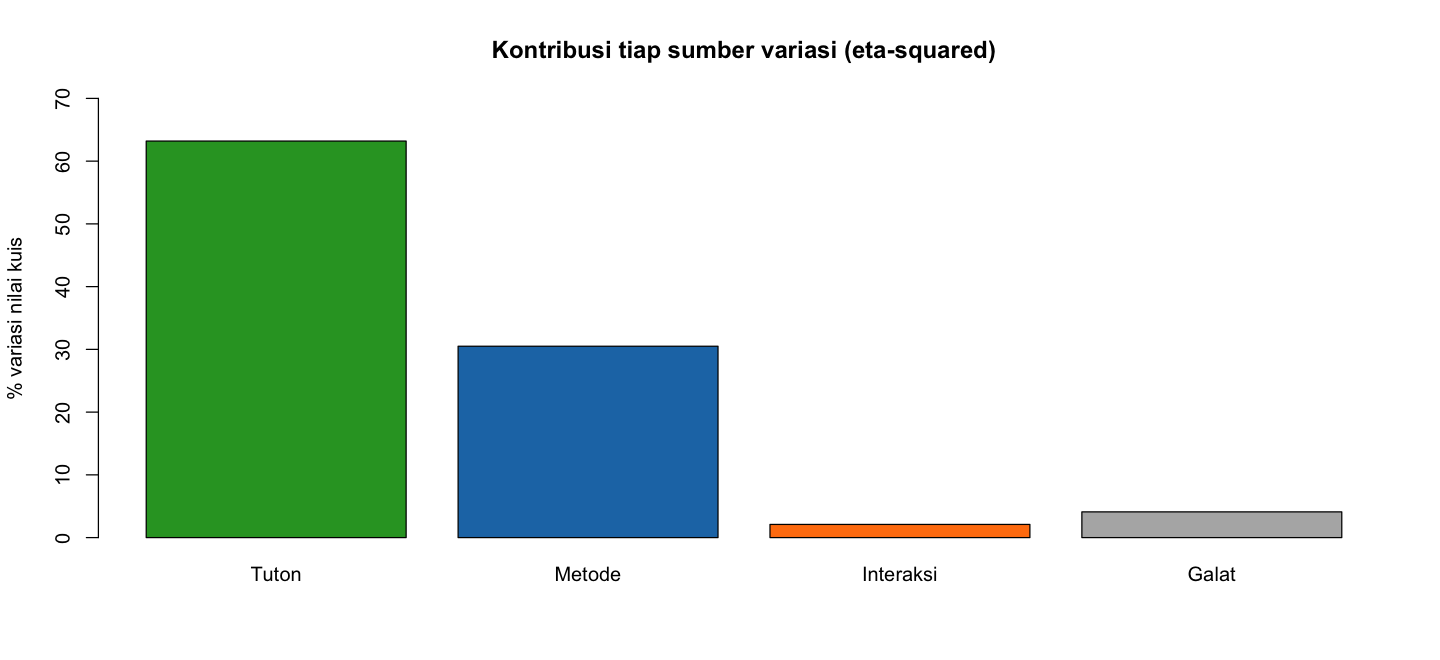

In [22]:
# Besar kontribusi tiap sumber variasi (eta-squared = JK / JK Total)
eta2 <- data.frame(
  Sumber      = c("Intensitas tuton (B)", "Metode belajar (A)", "Interaksi A x B", "Galat"),
  JK          = c(JK_B, JK_A, JK_AB, JK_G),
  "Eta2 (%)"  = round(100 * c(JK_B, JK_A, JK_AB, JK_G) / JK_T, 1),
  check.names = FALSE
)
print(eta2)

cat("\nKombinasi dengan rata-rata terendah (kelompok berisiko):\n")
print(tail(rata_sel, 3))

barplot(eta2[["Eta2 (%)"]], names.arg = c("Tuton", "Metode", "Interaksi", "Galat"),
        col = c("#2ca02c", "#1f77b4", "#ff7f0e", "grey70"), ylim = c(0, 70),
        ylab = "% variasi nilai kuis", main = "Kontribusi tiap sumber variasi (eta-squared)")

**Jawaban:**

Output menunjukkan intensitas tuton menjelaskan sekitar **63%** variasi nilai, metode belajar sekitar **31%**, dan interaksi hanya sekitar **2%**. Dari situ, tutor dapat:

- **Mendorong akses tuton secara rutin**, karena ini faktor paling berpengaruh. Caranya: pengingat berkala, aktivitas diskusi mingguan yang wajib, dan pemantauan mahasiswa yang jarang login.
- **Memperbanyak latihan soal di tuton**, karena metode ini memberi hasil terbaik. Contohnya kuis latihan tiap sesi, bank soal dengan pembahasan, dan tugas berbasis pemecahan masalah.
- **Memadukan metode, bukan mengganti.** BMP dan video tetap berguna untuk pemahaman konsep, tetapi sebaiknya selalu ditutup dengan latihan soal.
- **Memprioritaskan mahasiswa berisiko.** Kelompok dengan akses rendah yang hanya membaca BMP (rata-rata 65) perlu intervensi lebih awal, misalnya pesan personal atau sesi latihan tambahan.
- **Menerapkan strategi secara umum.** Karena interaksi tidak signifikan, strategi di atas berlaku untuk semua mahasiswa tanpa perlu dibedakan per kelompok akses.